# Predicción de entregas tardías en Olist
## PCA y evaluación de mejoras al modelo · Laboratorio Semana 14

**Data Analytics ML Challenge · 2026-2**
Profesor: Elias Buitrago Bolivar · Universidad Central
Caso: *Brazilian E-Commerce Public Dataset by Olist*

---

**Objetivo.** Evaluar si reducir la dimensión de las variables numéricas con PCA y modificar la regularización (`C`) de una regresión logística permite identificar mejor los pedidos que llegarían después de la fecha prometida.

**Contenido**

1. Carga de datos
2. Preparación de variables
3. Modelo de referencia
4. PCA y varianza explicada
5. Experimentos A, B, C y D
6. Prueba de Kolmogorov-Smirnov
7. Interpretación de negocio
8. Registro de resultados

> Las secciones 1 a 3 se suministran resueltas. Las instrucciones de GitHub y entrega se encuentran en el documento técnico.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [ ]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [ ]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [ ]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [ ]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [ ]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [ ]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [ ]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 11
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 11 | Semilla: 1011
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 22282eef00f8


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [ ]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


---
# Actividades del laboratorio

Se comparan **cuatro configuraciones** con la misma muestra, la misma partición, el mismo umbral de clasificación (0,50) y `class_weight='balanced'`. Solo cambian el uso de PCA y el valor de `C`, de modo que cada diferencia pueda atribuirse a un único cambio.

| Experimento | Variables numéricas | C | Comparación relevante |
|:--|:--|:--:|:--|
| **A.** Modelo de referencia | Originales, sin PCA | 1,0 | Punto de referencia |
| **B.** Reducción de dimensión | PCA (90 % de varianza) | 1,0 | B frente a A: efecto de PCA |
| **C.** Mayor penalización | PCA (90 % de varianza) | 0,1 | C frente a B: más regularización |
| **D.** Menor penalización | PCA (90 % de varianza) | 10,0 | D frente a B: menos regularización |

> **Recordatorio:** en regresión logística, un `C` menor significa una penalización **más fuerte**.

## 4. PCA: varianza explicada acumulada

PCA resume la información de las variables numéricas en componentes. Antes de aplicarlo se imputan los faltantes (mediana) y se estandarizan las variables; **ambas transformaciones se ajustan solo con entrenamiento** para evitar fuga de información. Se conserva el número mínimo de componentes que explica al menos el 90 % de la varianza.

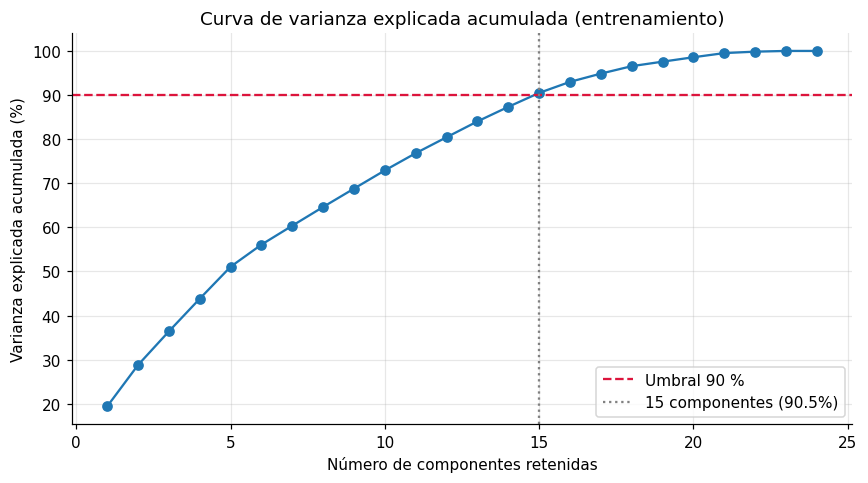

**Resultado.** Se partió de **24 variables numéricas** y se conservaron **15 componentes**, que explican el **90.5%** de la varianza. Esta cifra describe el espacio de variables; **no** equivale a la exactitud del modelo.

In [ ]:
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3})

UMBRAL = 0.50
COSTO_FP, COSTO_FN = 8, 35      # supuesto didáctico, no son costos reales de Olist

# Imputación y escala ajustadas únicamente con entrenamiento
prep_num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = prep_num.fit_transform(X_train[columnas_numericas])

pca_completo = PCA(svd_solver='full', random_state=semilla).fit(Z_train)
var_acum = np.cumsum(pca_completo.explained_variance_ratio_)
n_componentes = int(np.argmax(var_acum >= 0.90) + 1)
var_retenida = var_acum[n_componentes - 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(var_acum) + 1), var_acum * 100, marker='o', color='#1f77b4')
ax.axhline(90, color='crimson', linestyle='--', label='Umbral 90 %')
ax.axvline(n_componentes, color='gray', linestyle=':',
           label=f'{n_componentes} componentes ({var_retenida:.1%})')
ax.set_xlabel('Número de componentes retenidas')
ax.set_ylabel('Varianza explicada acumulada (%)')
ax.set_title('Curva de varianza explicada acumulada (entrenamiento)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

display(Markdown(
    f'**Resultado.** Se partió de **{len(columnas_numericas)} variables numéricas** y se '
    f'conservaron **{n_componentes} componentes**, que explican el **{var_retenida:.1%}** '
    f'de la varianza. Esta cifra describe el espacio de variables; '
    f'**no** equivale a la exactitud del modelo.'))

## 5. Experimentos A, B, C y D

Cada configuración es un `Pipeline` completo (imputación → escala → PCA opcional → One-Hot Encoding → regresión logística) ajustado con **entrenamiento** y evaluado en **validación**. El conjunto de prueba permanece reservado.

Convención de errores: **VP** = tardío detectado; **FN** = tardío no detectado (R$ 35); **FP** = falsa alerta (R$ 8); **VN** = puntual reconocido.

In [ ]:
categoricas = make_pipeline(SimpleImputer(strategy='most_frequent'),
                            OneHotEncoder(handle_unknown='ignore'))

def construir_modelo(usar_pca, C):
    if usar_pca:
        num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                            PCA(n_components=0.90, svd_solver='full', random_state=semilla))
    else:
        num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    prep = ColumnTransformer([('numericas', num, columnas_numericas),
                              ('categoricas', categoricas, columnas_categoricas)])
    clf = LogisticRegression(C=C, class_weight='balanced', max_iter=2000,
                             random_state=semilla)
    return make_pipeline(prep, clf)

experimentos = {
    'A. Referencia (sin PCA, C=1,0)': dict(usar_pca=False, C=1.0),
    'B. PCA 90 % (C=1,0)':            dict(usar_pca=True,  C=1.0),
    'C. PCA 90 % (C=0,1)':            dict(usar_pca=True,  C=0.1),
    'D. PCA 90 % (C=10,0)':           dict(usar_pca=True,  C=10.0),
}

filas, modelos = [], {}
for nombre, cfg in experimentos.items():
    modelo = construir_modelo(**cfg).fit(X_train, y_train)
    proba = modelo.predict_proba(X_valid)[:, 1]
    pred = (proba >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    filas.append({
        'Experimento': nombre, 'C': cfg['C'],
        'Componentes numéricas': (modelo[0].named_transformers_['numericas'][-1].n_components_
                                   if cfg['usar_pca'] else len(columnas_numericas)),
        'Accuracy': accuracy_score(y_valid, pred),
        'Precision': precision_score(y_valid, pred, zero_division=0),
        'Recall': recall_score(y_valid, pred),
        'F1': f1_score(y_valid, pred),
        'AP': average_precision_score(y_valid, proba),
        'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn,
        'Costo (R$)': COSTO_FP * fp + COSTO_FN * fn,
    })
    modelos[nombre] = modelo

resultados = pd.DataFrame(filas).set_index('Experimento')

try:   # tabla con el mejor valor resaltado en cada métrica
    display(resultados.style
            .format({'Accuracy': '{:.3f}', 'Precision': '{:.3f}', 'Recall': '{:.3f}',
                     'F1': '{:.3f}', 'AP': '{:.3f}', 'Costo (R$)': '{:,.0f}'})
            .highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1', 'AP'], color='#c8e6c9')
            .highlight_min(subset=['FP', 'FN', 'Costo (R$)'], color='#c8e6c9')
            .set_caption('Resultados en validación (verde = mejor valor de la columna)'))
except Exception:
    display(resultados.round(3))

,C,Componentes numéricas,Accuracy,Precision,Recall,F1,AP,VP,FP,FN,VN,Costo (R$)
Experimento,,,,,,,,,,,,
"A. Referencia (sin PCA, C=1,0)",1.000000,24,0.654,0.123,0.670,0.208,0.145,238,1700,117,3195,"17,695"
"B. PCA 90 % (C=1,0)",1.000000,15,0.638,0.109,0.606,0.185,0.126,215,1758,140,3137,"18,964"
"C. PCA 90 % (C=0,1)",0.100000,15,0.641,0.111,0.614,0.188,0.126,218,1746,137,3149,"18,763"
"D. PCA 90 % (C=10,0)",10.000000,15,0.638,0.109,0.608,0.185,0.126,216,1762,139,3133,"18,961"


### Visualización comparativa

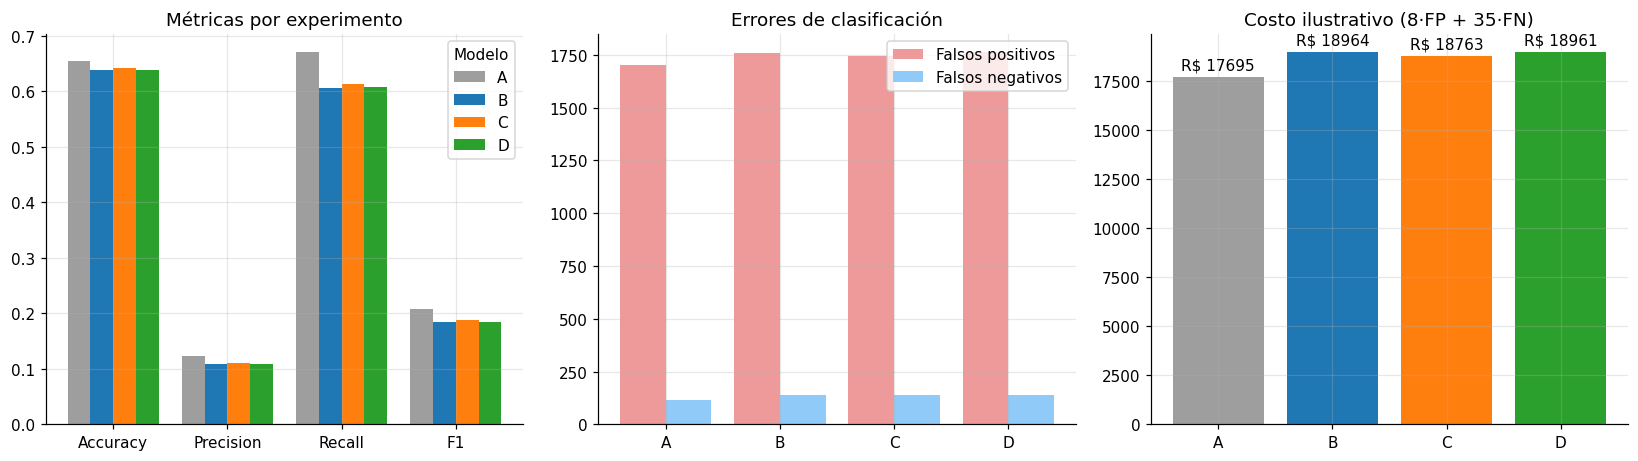

In [ ]:
etiquetas = ['A', 'B', 'C', 'D']
colores = ['#9e9e9e', '#1f77b4', '#ff7f0e', '#2ca02c']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3))

# 1. Métricas de clasificación
met = ['Accuracy', 'Precision', 'Recall', 'F1']
ancho = 0.2
for i, (et, col) in enumerate(zip(etiquetas, colores)):
    ejes[0].bar(np.arange(len(met)) + i * ancho, resultados.iloc[i][met].values,
                ancho, label=et, color=col)
ejes[0].set_xticks(np.arange(len(met)) + 1.5 * ancho); ejes[0].set_xticklabels(met)
ejes[0].set_title('Métricas por experimento'); ejes[0].legend(title='Modelo')

# 2. Falsos positivos y negativos
x = np.arange(4)
ejes[1].bar(x - 0.2, resultados['FP'], 0.4, label='Falsos positivos', color='#ef9a9a')
ejes[1].bar(x + 0.2, resultados['FN'], 0.4, label='Falsos negativos', color='#90caf9')
ejes[1].set_xticks(x); ejes[1].set_xticklabels(etiquetas)
ejes[1].set_title('Errores de clasificación'); ejes[1].legend()

# 3. Costo ilustrativo
barras = ejes[2].bar(etiquetas, resultados['Costo (R$)'], color=colores)
ejes[2].bar_label(barras, fmt='R$ %.0f', padding=3)
ejes[2].set_title(f'Costo ilustrativo ({COSTO_FP}·FP + {COSTO_FN}·FN)')

plt.tight_layout(); plt.show()

### Comparaciones controladas

Diferencia entre configuraciones (un solo cambio a la vez). En las métricas, un valor positivo significa que el segundo modelo es mayor; en **FP, FN y costo**, un valor negativo significa mejora.

In [ ]:
metricas = ['Accuracy', 'Precision', 'Recall', 'F1', 'AP', 'FP', 'FN', 'Costo (R$)']
comparacion = pd.DataFrame({
    'B − A (efecto de PCA)':           resultados.iloc[1][metricas] - resultados.iloc[0][metricas],
    'C − B (penalización mayor)':      resultados.iloc[2][metricas] - resultados.iloc[1][metricas],
    'D − B (penalización menor)':      resultados.iloc[3][metricas] - resultados.iloc[1][metricas],
})
display(comparacion.round(4))

,B − A (efecto de PCA),C − B (penalización mayor),D − B (penalización menor)
Accuracy,-0.0154,0.0029,-0.0006
Precision,-0.0138,0.0020,0.0002
Recall,-0.0648,0.0085,0.0028
F1,-0.0229,0.0033,0.0005
AP,-0.0183,-0.0006,-0.0004
FP,58.0000,-12.0000,4.0000
FN,23.0000,-3.0000,-1.0000
Costo (R$),1269.0000,-201.0000,-3.0000


## 6. Prueba de Kolmogorov-Smirnov: `valor_flete` en entrenamiento y validación

Se contrasta si la distribución del flete es compatible entre las dos particiones. La prueba compara **distribuciones**, no modelos.

- **H₀:** `valor_flete` tiene la misma distribución en entrenamiento y validación.
- **H₁:** las distribuciones son diferentes.
- **Nivel de significancia:** α = 0,05.

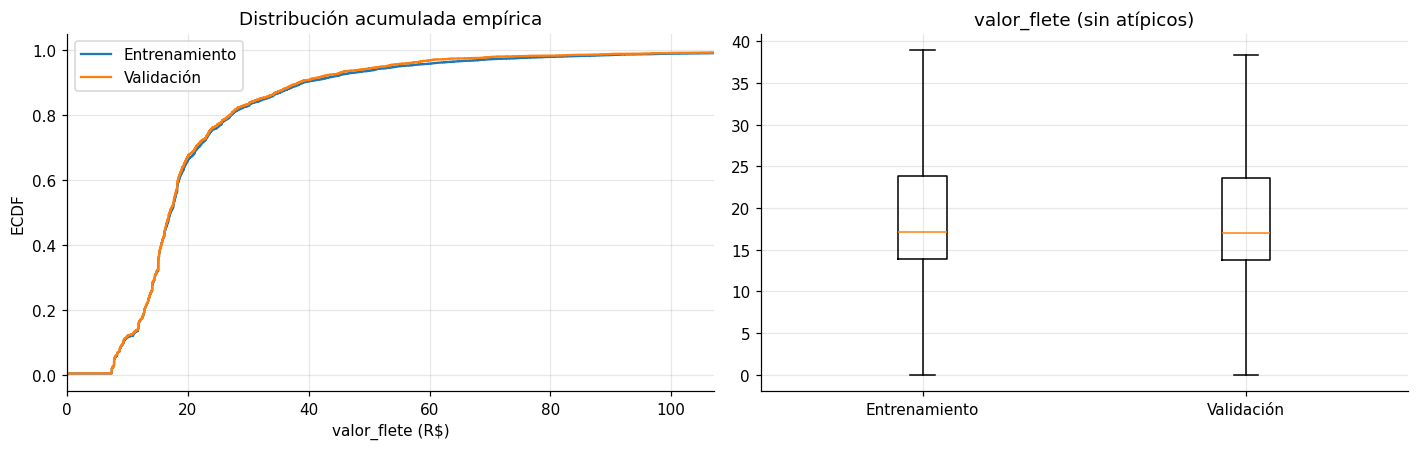

,Entrenamiento,Validación
count,24500.00,5250.00
mean,22.83,22.20
std,21.10,19.94
min,0.00,0.00
25%,13.83,13.78
50%,17.16,17.01
75%,23.88,23.60
max,711.33,502.98


**Resultado.** n entrenamiento = 24,500 · n validación = 5,250 · **D = 0.0133** · **p = 0.4207** → decisión con α = 0,05: **no rechazar H₀**.

In [ ]:
flete_tr = train['valor_flete'].dropna()
flete_va = valid['valor_flete'].dropna()

resultado_ks = ks_2samp(flete_tr, flete_va, alternative='two-sided')
D_ks, p_ks = resultado_ks.statistic, resultado_ks.pvalue
decision_ks = 'rechazar H₀' if p_ks < 0.05 else 'no rechazar H₀'

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for datos, nombre, col in [(flete_tr, 'Entrenamiento', '#1f77b4'),
                           (flete_va, 'Validación', '#ff7f0e')]:
    x = np.sort(datos.values)
    ejes[0].step(x, np.arange(1, len(x) + 1) / len(x), label=nombre, color=col)
ejes[0].set_xlim(0, flete_tr.quantile(0.99)); ejes[0].set_xlabel('valor_flete (R$)')
ejes[0].set_ylabel('ECDF'); ejes[0].set_title('Distribución acumulada empírica'); ejes[0].legend()
ejes[1].boxplot([flete_tr, flete_va], showfliers=False)
ejes[1].set_xticklabels(['Entrenamiento', 'Validación'])
ejes[1].set_title('valor_flete (sin atípicos)')
plt.tight_layout(); plt.show()

display(pd.DataFrame({'Entrenamiento': flete_tr.describe(),
                      'Validación': flete_va.describe()}).round(2))

display(Markdown(
    f'**Resultado.** n entrenamiento = {len(flete_tr):,} · n validación = {len(flete_va):,} · '
    f'**D = {D_ks:.4f}** · **p = {p_ks:.4f}** → decisión con α = 0,05: **{decision_ks}**.'))

## 7. Interpretación de negocio

El texto siguiente se genera a partir de los resultados calculados en este mismo notebook, por lo que se actualiza solo si se cambia el ID. Primero se presentan los **hechos observados**; la decisión depende además de los **supuestos de costo**.

In [ ]:
A, B, C, D = [resultados.iloc[i] for i in range(4)]

def mov(nuevo, base, col, mayor_es_mejor=True):
    d = nuevo[col] - base[col]
    if abs(d) < 1e-12: return 'se mantuvo igual'
    mejora = (d > 0) == mayor_es_mejor
    return ('mejoró' if mejora else 'empeoró')

def fmt(v, col):
    return f'{v:.3f}' if col in ('Accuracy','Precision','Recall','F1','AP') else f'{v:,.0f}'

def linea(nuevo, base, col, mayor=True):
    return (f'{col} {mov(nuevo, base, col, mayor)} '
            f'({fmt(base[col], col)} → {fmt(nuevo[col], col)})')

mejor_costo = resultados['Costo (R$)'].idxmin()
mejor_acc, mejor_rec = resultados['Accuracy'].idxmax(), resultados['Recall'].idxmax()
mejor_f1 = resultados['F1'].idxmax()
ahorro_vs_A = A['Costo (R$)'] - resultados.loc[mejor_costo, 'Costo (R$)']
pct_ahorro = 100 * ahorro_vs_A / A['Costo (R$)']

texto = f'''
### 7.1 Efecto de PCA (B frente a A)
Se partió de **{len(columnas_numericas)} variables numéricas** y se conservaron **{n_componentes} componentes**
(**{var_retenida:.1%}** de varianza). Con el mismo `C = 1,0`, al aplicar PCA: {linea(B, A, 'Recall')};
{linea(B, A, 'F1')}; {linea(B, A, 'FN', False)}; {linea(B, A, 'Costo (R$)', False)}.
Como PCA maximiza varianza y no capacidad predictiva, la compresión pudo descartar información útil
para separar entregas puntuales y tardías.

### 7.2 Efecto de la regularización (C y D frente a B)
- **C = 0,1 (penalización mayor):** {linea(C, B, 'Recall')}; {linea(C, B, 'FN', False)}; {linea(C, B, 'Costo (R$)', False)}.
- **C = 10,0 (penalización menor):** {linea(D, B, 'Recall')}; {linea(D, B, 'FN', False)}; {linea(D, B, 'Costo (R$)', False)}.

Si las diferencias son pequeñas, no demuestran por sí solas una mejora estadísticamente concluyente.

### 7.3 ¿Qué modelo elegir?
| Criterio | Modelo que lo maximiza / minimiza |
|:--|:--|
| Mayor Accuracy | {mejor_acc} |
| Mayor Recall | {mejor_rec} |
| Mayor F1 | {mejor_f1} |
| **Menor costo ilustrativo** | **{mejor_costo}** (R$ {resultados.loc[mejor_costo, 'Costo (R$)']:,.0f}) |

Bajo el supuesto de **R$ {COSTO_FP} por falso positivo y R$ {COSTO_FN} por falso negativo**, la opción de menor costo
es **{mejor_costo}**, con un ahorro de R$ {ahorro_vs_A:,.0f} ({pct_ahorro:.1f} %) frente a la referencia A.
Un modelo con mayor Accuracy no es necesariamente el mejor: como los retrasos son la clase minoritaria,
la Accuracy puede ser alta aunque se dejen pasar muchos pedidos tardíos. Estas cifras son supuestos didácticos
y no incluyen el costo fijo de operar un sistema de alertas.

### 7.4 Prueba KS sobre `valor_flete`
Con **D = {D_ks:.4f}** y **p = {p_ks:.4f}**, la decisión al nivel α = 0,05 es **{decision_ks}**.
{'Hay evidencia de diferencia entre las distribuciones de entrenamiento y validación.' if p_ks < 0.05
 else 'No hay evidencia suficiente de diferencia entre las particiones; esto **no** demuestra que sean idénticas.'}

**Limitaciones:** (i) el flete tiene valores repetidos y redondeados a centavos, y KS asume una variable continua;
(ii) con muestras grandes se detectan diferencias operativamente irrelevantes; (iii) KS compara la distribución
de una variable entre particiones, **no** el desempeño de los modelos ni permite declarar a uno estadísticamente superior.
'''
display(Markdown(texto))


### 7.1 Efecto de PCA (B frente a A)
Se partió de **24 variables numéricas** y se conservaron **15 componentes**
(**90.5%** de varianza). Con el mismo `C = 1,0`, al aplicar PCA: Recall empeoró (0.670 → 0.606);
F1 empeoró (0.208 → 0.185); FN empeoró (117 → 140); Costo (R$) empeoró (17,695 → 18,964).
Como PCA maximiza varianza y no capacidad predictiva, la compresión pudo descartar información útil
para separar entregas puntuales y tardías.

### 7.2 Efecto de la regularización (C y D frente a B)
- **C = 0,1 (penalización mayor):** Recall mejoró (0.606 → 0.614); FN mejoró (140 → 137); Costo (R$) mejoró (18,964 → 18,763).
- **C = 10,0 (penalización menor):** Recall mejoró (0.606 → 0.608); FN mejoró (140 → 139); Costo (R$) mejoró (18,964 → 18,961).

Si las diferencias son pequeñas, no demuestran por sí solas una mejora estadísticamente concluyente.

### 7.3 ¿Qué modelo elegir?
| Criterio | Modelo que lo maximiza / minimiza |
|:--|:--|
| Mayor Accuracy | A. Referencia (sin PCA, C=1,0) |
| Mayor Recall | A. Referencia (sin PCA, C=1,0) |
| Mayor F1 | A. Referencia (sin PCA, C=1,0) |
| **Menor costo ilustrativo** | **A. Referencia (sin PCA, C=1,0)** (R$ 17,695) |

Bajo el supuesto de **R$ 8 por falso positivo y R$ 35 por falso negativo**, la opción de menor costo
es **A. Referencia (sin PCA, C=1,0)**, con un ahorro de R$ 0 (0.0 %) frente a la referencia A.
Un modelo con mayor Accuracy no es necesariamente el mejor: como los retrasos son la clase minoritaria,
la Accuracy puede ser alta aunque se dejen pasar muchos pedidos tardíos. Estas cifras son supuestos didácticos
y no incluyen el costo fijo de operar un sistema de alertas.

### 7.4 Prueba KS sobre `valor_flete`
Con **D = 0.0133** y **p = 0.4207**, la decisión al nivel α = 0,05 es **no rechazar H₀**.
No hay evidencia suficiente de diferencia entre las particiones; esto **no** demuestra que sean idénticas.

**Limitaciones:** (i) el flete tiene valores repetidos y redondeados a centavos, y KS asume una variable continua;
(ii) con muestras grandes se detectan diferencias operativamente irrelevantes; (iii) KS compara la distribución
de una variable entre particiones, **no** el desempeño de los modelos ni permite declarar a uno estadísticamente superior.


### Conclusión personal (redactar)

> Escriba en 3 a 5 líneas su recomendación final: qué modelo elegiría, qué cambió entre experimentos, qué errores se reducen o aumentan y qué decisión de logística se derivaría. Distinga lo **observado** de los **supuestos**.

*(Escriba aquí su conclusión)*

## 8. Registro de resultados

Se guardan en `reports/` la bitácora de experimentos y un resumen en JSON, con el ID, la semilla y la huella de la muestra. **No** se publica la muestra de pedidos ni los archivos originales.

In [ ]:
Path('reports').mkdir(exist_ok=True)

registro = resultados.reset_index().copy()
registro.insert(0, 'ID', identificador)
registro.insert(1, 'semilla', semilla)
registro.insert(2, 'huella_muestra', huella_muestra)
registro['umbral'] = UMBRAL
registro.to_csv('reports/registro_experimentos_S14.csv', index=False)

resumen = {
    'id_estudiante': identificador, 'semilla': semilla, 'huella_muestra': huella_muestra,
    'variables_numericas': len(columnas_numericas), 'componentes_pca_90': n_componentes,
    'varianza_retenida': round(float(var_retenida), 4),
    'costo_fp': COSTO_FP, 'costo_fn': COSTO_FN, 'umbral': UMBRAL,
    'modelo_menor_costo': mejor_costo,
    'ks_valor_flete': {'D': float(D_ks), 'p': float(p_ks), 'decision_5pct': decision_ks},
}
Path('reports/resumen_S14.json').write_text(json.dumps(resumen, indent=2, ensure_ascii=False))

print('Archivos guardados en reports/:')
for f in sorted(Path('reports').iterdir()): print(' -', f.name)
print()
print(json.dumps(resumen, indent=2, ensure_ascii=False))

Archivos guardados en reports/:
 - registro_experimentos_S14.csv
 - resumen_S14.json

{
  "id_estudiante": "11",
  "semilla": 1011,
  "huella_muestra": "22282eef00f8",
  "variables_numericas": 24,
  "componentes_pca_90": 15,
  "varianza_retenida": 0.9049,
  "costo_fp": 8,
  "costo_fn": 35,
  "umbral": 0.5,
  "modelo_menor_costo": "A. Referencia (sin PCA, C=1,0)",
  "ks_valor_flete": {
    "D": 0.013346938775510298,
    "p": 0.4206694940535485,
    "decision_5pct": "no rechazar H₀"
  }
}
